# Feature checks for clustering

Correlation, encoding, scaling and extreme-value checks for the variables proposed in
`docs/feature_roles_proposal.md`.

Run this notebook from the `notebooks/` directory. The input is
`../data/processed/student_data_preprocessed.csv`, generated by `data_preprocessing.ipynb`.

## Load the preprocessed data

The loading options keep the literal education category "None" distinct from missing values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df = pd.read_csv('../data/processed/student_data_preprocessed.csv',
                 keep_default_na=False, na_values=[''],
                 index_col='student_row_id')
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
student_row_id,,,,,,,,,,,,,,,,,,,,,
0,GP,F,18,U,7.0,A,Higher Education,Higher Education,at_home,teacher,...,4.0,3.0,4.0,1.0,1.0,3.0,4.0,0,11,11
1,GP,F,17,U,4.0,T,Primary Education,Primary Education,at_home,other,...,5.0,3.0,3.0,1.0,1.0,3.0,2.0,9,11,11
2,GP,F,15,U,1.0,T,Primary Education,Primary Education,at_home,other,...,4.0,3.0,2.0,2.0,2.0,3.0,6.0,12,13,12
3,GP,F,15,U,4.0,T,Higher Education,Middle School Education,health,services,...,3.0,2.0,2.0,1.0,1.0,5.0,0.0,14,14,14
4,GP,F,16,U,9.0,T,Secondary Education,Secondary Education,other,other,...,4.0,3.0,2.0,1.0,2.0,5.0,0.0,11,13,13


## New features

- `total_alc = Dalc + Walc` (2 to 10): weekday and weekend alcohol measure the same concept (r = 0.62),
  so they are combined to avoid counting alcohol twice.
- `parent_edu` (0 to 4): highest education level of the two parents (Medu and Fedu, r = 0.64).
  If one parent is unknown, the other one is used, so only students with both parents unknown stay missing.

In [2]:
# total_alc: weekday + weekend alcohol consumption (2 to 10)
df['total_alc'] = df['Dalc'] + df['Walc']

# parent_edu: highest education level of the two parents (0 to 4)
edu_order = {'None': 0, 'Primary Education': 1, 'Middle School Education': 2,
             'Secondary Education': 3, 'Higher Education': 4}
medu_num = df['Medu'].map(edu_order)
fedu_num = df['Fedu'].map(edu_order)
df['parent_edu'] = pd.concat([medu_num, fedu_num], axis=1).max(axis=1)

print(df['parent_edu'].value_counts(dropna=False).sort_index())

parent_edu
0.0      1
1.0    105
2.0    189
3.0    149
4.0    203
NaN      2
Name: count, dtype: int64


## Correlations within each perspective

Spearman correlations on the preprocessed data, because most variables are ordinal (1–5 ratings,
`parent_edu`) or binary. Yes/No answers are encoded as 1/0; "Unknown" is ignored in this check.
A pair above |r| = 0.8 would mean that one variable repeats another.

In [3]:
yes_no = {'yes': 1, 'no': 0}   # 'Unknown' becomes NaN and is ignored in the correlation

academic = pd.DataFrame({
    'G3': df['G3'], 'failures': df['failures'], 'studytime': df['studytime'],
    'higher': df['higher'].map(yes_no)
})
habits = pd.DataFrame({
    'absences': df['absences'], 'goout': df['goout'], 'freetime': df['freetime'],
    'total_alc': df['total_alc'], 'activities': df['activities'].map(yes_no)
})
family = pd.DataFrame({
    'parent_edu': df['parent_edu'], 'famrel': df['famrel'],
    'famsup': df['famsup'].map(yes_no), 'internet': df['internet'].map(yes_no)
})

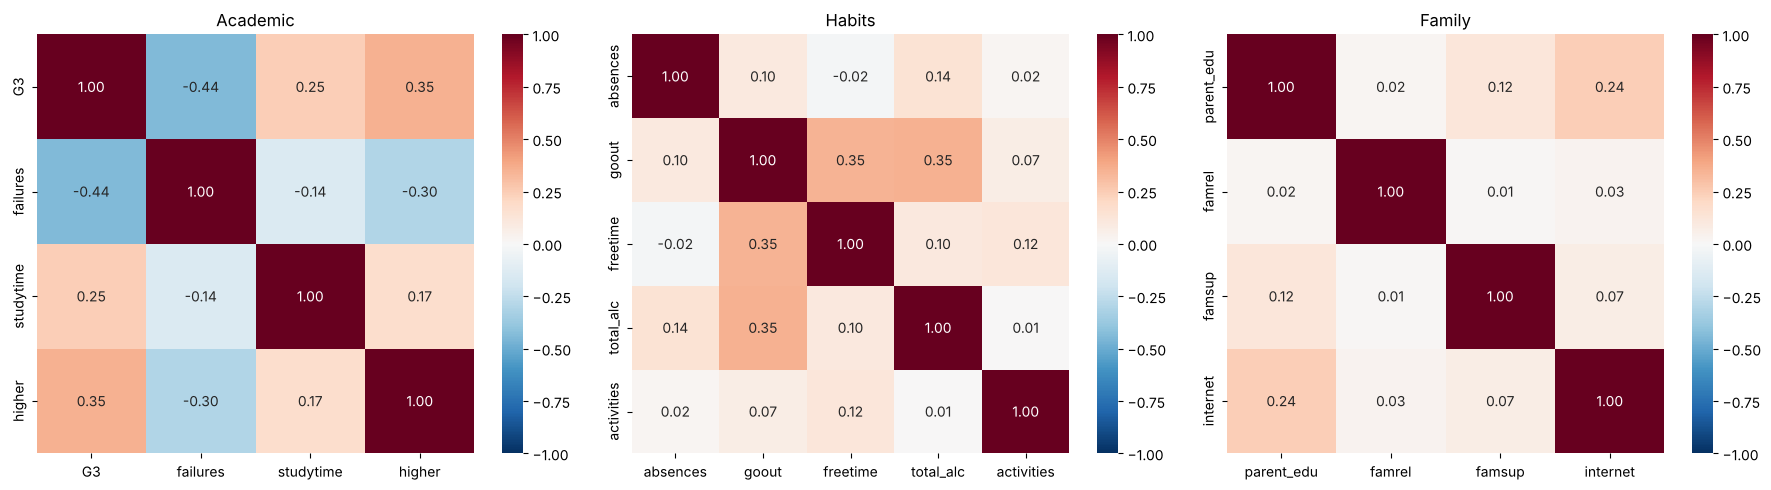

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, table) in zip(axes, [('Academic', academic),
                                    ('Habits', habits),
                                    ('Family', family)]):
    sns.heatmap(table.corr(method='spearman'), annot=True, fmt='.2f',
                cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [5]:
for name, table in [('Academic', academic), ('Habits', habits), ('Family', family)]:
    corr = table.corr(method='spearman')
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
    high = upper[upper.abs() > 0.8]
    print(name, '→', 'no pair above 0.8' if high.empty else high.to_dict())

Academic → no pair above 0.8
Habits → no pair above 0.8
Family → no pair above 0.8


**Result:** no pair is above 0.8, so no variable is redundant. The strongest relationships are
moderate and expected: G3–failures (−0.44) and G3–higher (0.35); goout–freetime and goout–total_alc
(0.35); parent_edu–internet (0.24). Family variables are only weakly related to each other.

## Encoding

For the main clustering version, "Unknown" Yes/No answers are replaced with the mode (group decision),
so each Yes/No variable stays a single 0/1 column. The two students with both parents' education unknown
get the median `parent_edu`.

In [6]:
binary_cols = ['higher', 'activities', 'famsup', 'internet']
for col in binary_cols:
    mode = df.loc[df[col] != 'Unknown', col].mode()[0]
    df[col] = df[col].replace('Unknown', mode).map(yes_no)
    print(col, '→ mode:', mode)

df['parent_edu'] = df['parent_edu'].fillna(df['parent_edu'].median())

higher → mode: yes
activities → mode: no
famsup → mode: yes
internet → mode: yes


In [7]:
perspectives = {
    'academic': ['G3', 'failures', 'studytime', 'higher'],
    'habits':   ['absences', 'goout', 'freetime', 'total_alc', 'activities'],
    'family':   ['parent_edu', 'famrel', 'famsup', 'internet'],
}
for name, cols in perspectives.items():
    print(name, '→ missing values:', df[cols].isna().sum().sum())

academic → missing values: 0
habits → missing values: 0
family → missing values: 0


## Scaling: MinMax vs StandardScaler

Share of the distance taken by each variable after scaling (its variance divided by the sum of the
variances). With MinMax, a single binary variable takes about half of each perspective's distance,
because 0/1 values always sit at the extremes, while absences is squeezed by a few very high values.
With StandardScaler every variable has variance 1, so all variables weigh the same.

In [8]:
for name, cols in perspectives.items():
    for scaler in [MinMaxScaler(), StandardScaler()]:
        scaled = pd.DataFrame(scaler.fit_transform(df[cols]), columns=cols)
        weight = scaled.var() / scaled.var().sum() * 100   # share of the distance (%)
        print(f'{name:9s} {type(scaler).__name__:15s}', weight.round(1).to_dict())
    print()

academic  MinMaxScaler    {'G3': 15.8, 'failures': 20.5, 'studytime': 13.9, 'higher': 49.9}
academic  StandardScaler  {'G3': 25.0, 'failures': 25.0, 'studytime': 25.0, 'higher': 25.0}

habits    MinMaxScaler    {'absences': 4.4, 'goout': 17.3, 'freetime': 14.0, 'total_alc': 12.4, 'activities': 51.9}
habits    StandardScaler  {'absences': 20.0, 'goout': 20.0, 'freetime': 20.0, 'total_alc': 20.0, 'activities': 20.0}

family    MinMaxScaler    {'parent_edu': 13.5, 'famrel': 10.2, 'famsup': 43.7, 'internet': 32.6}
family    StandardScaler  {'parent_edu': 25.0, 'famrel': 25.0, 'famsup': 25.0, 'internet': 25.0}



## Extreme values (studytime and absences)

Only these two variables need treatment, because traveltime only describes the clusters.
First, how many students lie above the upper whisker of the boxplot (IQR rule), and how the
percentiles grow towards the top.

studytime: upper whisker = 547, students above = 53 (8.2%)
{0.5: 186.0, 0.75: 280.0, 0.9: 510.0, 0.95: 673.0, 0.99: 1304.0, 1.0: 1465.0} 

absences: upper whisker = 15, students above = 20 (3.1%)
{0.5: 2.0, 0.75: 6.0, 0.9: 10.0, 0.95: 12.0, 0.99: 21.0, 1.0: 32.0} 



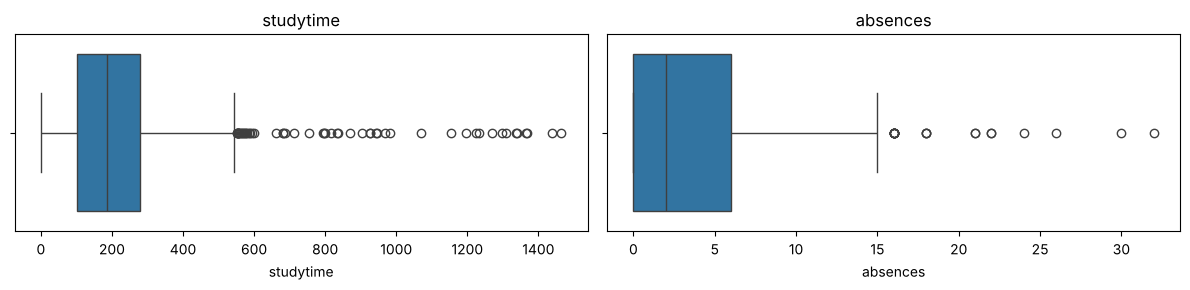

In [9]:
for col in ['studytime', 'absences']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)          # IQR rule: upper whisker of the boxplot
    n_out = (df[col] > upper).sum()
    print(f'{col}: upper whisker = {upper:.0f}, students above = {n_out} ({n_out/len(df)*100:.1f}%)')
    print(df[col].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1]).round(0).to_dict(), '\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, col in zip(axes, ['studytime', 'absences']):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Are the extreme values real? If they were recording errors they would not be related to other
variables. We compare the grades and past failures of the extreme students with the rest.

In [10]:
for col in ['studytime', 'absences']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    is_extreme = df[col] > upper
    print(col)
    print(df.groupby(is_extreme)[['G3', 'failures']].mean().round(2)
            .rename(index={False: 'rest', True: 'extremes'}))
    print(df.sort_values(col, ascending=False)[[col, 'G3', 'failures', 'school']].head(5), '\n')

studytime
              G3  failures
studytime                 
rest       11.79      0.23
extremes   13.19      0.09
                studytime  G3  failures school
student_row_id                                
66                 1465.0  12       0.0     GP
503                1439.0  14       0.0     MS
298                1368.0  12       0.0     GP
312                1366.0  16       0.0     GP
149                1339.0  11       0.0     GP 

absences
             G3  failures
absences                 
rest      11.94      0.21
extremes  10.70      0.35
                absences  G3  failures school
student_row_id                               
197                 32.0  14       0.0     GP
212                 30.0  16       1.0     GP
256                 26.0   8       1.0     GP
150                 24.0   9       0.0     GP
155                 22.0   6       0.0     GP 



The extreme values are real: students who study the most get higher grades and have fewer past
failures, and students with the most absences get lower grades and have more past failures.

Options compared: skew (0 = symmetric, above 1 = long tail), the lowest and highest z-score after
standardising, and the number of students more than 3 standard deviations away.

In [11]:
def zscore(s):
    return (s - s.mean()) / s.std()

for col in ['studytime', 'absences']:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    options = {
        'keep':  s,
        'clip':  s.clip(upper=q3 + 1.5 * (q3 - q1)),
        'sqrt':  np.sqrt(s),
        'log1p': np.log1p(s),
    }
    print(col)
    for name, values in options.items():
        z = zscore(values)
        print(f'  {name:6s} skew = {values.skew():5.2f} | z from {z.min():5.1f} to {z.max():4.1f} '
              f'| students with |z| > 3: {(z.abs() > 3).sum()}')
    print()

studytime
  keep   skew =  2.55 | z from  -1.0 to  5.2 | students with |z| > 3: 18
  clip   skew =  0.85 | z from  -1.4 to  2.2 | students with |z| > 3: 0
  sqrt   skew =  0.92 | z from  -2.2 to  3.7 | students with |z| > 3: 13
  log1p  skew = -1.25 | z from  -4.7 to  2.1 | students with |z| > 3: 11

absences
  keep   skew =  2.07 | z from  -0.8 to  6.1 | students with |z| > 3: 11
  clip   skew =  1.29 | z from  -0.8 to  2.8 | students with |z| > 3: 0
  sqrt   skew =  0.45 | z from  -1.1 to  3.3 | students with |z| > 3: 2
  log1p  skew =  0.25 | z from  -1.1 to  2.5 | students with |z| > 3: 0



## Treatment

- **absences:** log-transformed (`log1p`, which also handles the zeros): nearly symmetric and no student
  with |z| > 3.
- **studytime:** capped at the upper whisker (547 minutes): no student with |z| > 3. A log transform
  was not used because three students with 0–2 minutes would become new extremes at the bottom (z = −4.7).

The transformed columns are used only for the clustering; the original columns are kept for profiling.

In [12]:
# Clustering versions only: original columns stay unchanged for profiling
q1, q3 = df['studytime'].quantile([0.25, 0.75])
study_upper = q3 + 1.5 * (q3 - q1)                       # 547 minutes
df['studytime_clip'] = df['studytime'].clip(upper=study_upper)
df['absences_log'] = np.log1p(df['absences'])

# Check: z-scores after the treatment
for col in ['studytime_clip', 'absences_log']:
    z = zscore(df[col])
    print(f'{col}: skew = {df[col].skew():.2f} | z from {z.min():.1f} to {z.max():.1f} '
          f'| students with |z| > 3: {(z.abs() > 3).sum()}')

studytime_clip: skew = 0.85 | z from -1.4 to 2.2 | students with |z| > 3: 0
absences_log: skew = 0.25 | z from -1.1 to 2.5 | students with |z| > 3: 0
